# Tipologi kondisi pertumbuhan, kelompok A–J

ditulis: tim PSE Atha Bintang Wahyu M. | PSE UGM

Notebook kerangka menghitung RTS, peringkat, pilar, dan pangsa, lalu menyimpan `tipologi_prov.csv`. Sel di bawah ini membaca tabel itu, menyusun kalimat kasus, dan menggambar. Pertanyaan investasi bukan efek yang sudah terbukti.

Urutannya: kondisi terukur, basis produksi, ciri, kendala, pembanding, lalu pertanyaan dan ukuran keberhasilan.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

def find_root():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "02 Code" / "BKPM" / "2026bkpm.Rproj").exists():
            return cand
    return Path("/Users/athamawardi/Desktop/Research-Projects/RDSI_Kemeninves")

ROOT = find_root()
OUT = ROOT / "01 Data" / "TFP" / "output" / "tipologi"
NAVY, CYAN, RED, TEAL, CREAM, GRAY, KERTAS = (
    "#0E2440", "#5DD0E6", "#D9042B", "#46A694", "#F2E6CE", "#797F8C", "#ffffff",
)
WARNA_KAT = {
    "A": "#0E2440", "B": "#D9042B", "C": "#0E7C66", "D": "#1A6F8A",
    "E": "#C47B2B", "F": "#6B4C7A", "G": "#8C3A3A", "H": "#3D6B8C",
    "I": "#2F6F4F", "J": "#A33B73",
}
GARIS = [
    "#0E2440", "#D9042B", "#0E7C66", "#C47B2B", "#6B4C7A", "#1A6F8A",
    "#A33B73", "#3D6B8C", "#8A6A32", "#3E5C76", "#B85C38", "#2C6E49",
]
KELOMPOK = [
    ("Pertanian", "#E4D3A8"), ("Pertambangan", "#D9042B"), ("Industri", "#0E2440"),
    ("Utilitas dan konstruksi", "#46A694"), ("Jasa", "#5DD0E6"),
]
HURUF = ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K", "L", "MN", "O", "P", "Q", "RSTU"]
JASA_RINCI = [
    ("Perdagangan", ["G"]), ("Transportasi", ["H"]), ("Akomodasi dan makan", ["I"]),
    ("Jasa lain", ["J", "K", "L", "MN", "O", "P", "Q", "RSTU"]),
]
CMAP = LinearSegmentedColormap.from_list("z", ["#8C3A3A", "#F7F1E8", "#0E2440"])
plt.rcParams.update({
    "figure.facecolor": KERTAS, "axes.facecolor": KERTAS, "axes.edgecolor": GRAY,
    "axes.grid": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12,
    "axes.titlecolor": NAVY, "axes.labelcolor": NAVY,
    "xtick.color": NAVY, "ytick.color": NAVY, "text.color": NAVY,
    "axes.unicode_minus": False, "legend.frameon": False,
})

def simpan(fig, name):
    path = OUT / name
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor=KERTAS)
    print(path.relative_to(ROOT))
    plt.show()
    plt.close(fig)

def bersih(ax, grid="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis=grid)
    if grid == "y":
        ax.grid(axis="x", visible=False)
    elif grid == "x":
        ax.grid(axis="y", visible=False)

def judul(ax, teks):
    ax.set_title(teks, loc="left", color=NAVY, fontsize=12, pad=8)

def koma(x, n=2, tanda=False):
    if pd.isna(x):
        return "—"
    teks = f"{x:+.{n}f}" if tanda else f"{x:.{n}f}"
    return teks.replace(".", ",")

def zscore(series):
    sd = series.std(ddof=0)
    if sd == 0 or np.isnan(sd):
        return series * 0
    return (series - series.mean()) / sd

prov = pd.read_csv(OUT / "tipologi_prov.csv")
panel = pd.read_csv(OUT / "tipologi_panel.csv")
kel = pd.read_csv(OUT / "tipologi_kelompok.csv")
for df, kolom in ((prov, "code"), (panel, "Code_Prov"), (kel, "Code_Prov")):
    df[kolom] = df[kolom].astype(int)
    if "Year" in df.columns:
        df["Year"] = df["Year"].astype(int)
SHORT = dict(zip(prov.code, prov.short))

# Pembanding nasional dihitung ulang dari panel, bukan disalin sebagai angka jadi.
d = panel[panel.Year.between(2017, 2024)].copy()
X = []
for col in ("log_Y", "log_K", "log_L"):
    X.append(
        d[col]
        - d.groupby("Code_Prov")[col].transform("mean")
        - d.groupby("Year")[col].transform("mean")
        + d[col].mean()
    )
b_fe, *_ = np.linalg.lstsq(np.column_stack(X[1:]), X[0], rcond=None)
rts_fe = float(b_fe.sum())
print(f"FE dua arah  b1 {b_fe[0]:.3f}  b2 {b_fe[1]:.3f}  jumlah {rts_fe:.3f}")

# Pangsa jasa dihitung terhadap seluruh tenaga kerja, bukan terhadap jumlah pekerja jasa saja.
sek = pd.read_excel(ROOT / "01 Data/TFP/output/konstruksi/TFP Provinsi 2017-2025.xlsx", sheet_name="sektor")
sek["Code_Prov"] = sek.Code_Prov.astype(int)
sek["Year"] = sek.Year.astype(int)
sek = sek[sek.Year.between(2017, 2024)].copy()
bagian = []
for nama, huruf in JASA_RINCI:
    bagian.append(pd.DataFrame({
        "Code_Prov": sek.Code_Prov.to_numpy(),
        "Year": sek.Year.to_numpy(),
        "kelompok": nama,
        "va": sek[[f"{h}_ADHK" for h in huruf]].sum(axis=1).to_numpy(),
        "tk": sek[[f"{h}_TenagaKerja" for h in huruf]].sum(axis=1).to_numpy(),
    }))
jasa = pd.concat(bagian, ignore_index=True)
tk_semua = sek[[f"{h}_TenagaKerja" for h in HURUF]].sum(axis=1)
jasa = jasa.merge(
    pd.DataFrame({"Code_Prov": sek.Code_Prov, "Year": sek.Year, "tk_semua": tk_semua.to_numpy()}),
    on=["Code_Prov", "Year"],
)
jasa["share_tk_semua"] = jasa.tk / jasa.tk_semua
jasa["lp"] = np.where(jasa.tk > 0, jasa.va * 1000 / jasa.tk, np.nan)


FE dua arah  b1 0.387  b2 0.193  jumlah 0.580


## Tabel kasus

Ciri memakai variabel dengan |z| terbesar. Kelompok dengan kurang dari tiga anggota dibandingkan ke 34 provinsi. Kelompok yang lebih besar dibandingkan di dalam kelompoknya sendiri. Kemiskinan dan TPT tetap dalam persen, tidak dicampur ke skor pilar.


In [2]:
UKURAN = {
    "A": "Upah riil, pengangguran terbuka, dan pangsa kerja di luar sektor yang mendominasi nilai tambah.",
    "B": "Output per pekerja, upah riil, dan apakah tenaga kerja bergerak bersama nilai tambah sektoral.",
    "C": "Output per pekerja, tren residual, dan diversifikasi pangsa nilai tambah.",
    "D": "Selisih pangsa nilai tambah dan tenaga kerja, upah riil, serta ekuitas, institusi, dan konektivitas.",
    "E": "Nilai tambah riil per pekerja di dalam sektor, bukan hanya skala tenaga kerja.",
    "F": "Nilai tambah per pekerja di pertanian dan di pertambangan, secara terpisah, serta tren residual.",
    "G": "Pangsa tenaga kerja versus pangsa nilai tambah, upah riil, kemiskinan, dan pendidikan.",
    "H": "Apakah lama sekolah diikuti upah riil yang lebih tinggi dan output per pekerja yang lebih tinggi.",
    "I": "Tren residual, posisi pada spesifikasi CRS, dan konektivitas.",
    "J": "Pilar yang lemah pada provinsi itu, output per pekerja, dan bagi Bali kualitas kerja jasa.",
}
BANDING = {
    31: ([36, 32], [14]), 14: ([21, 15], [31]),
    82: ([81], [72]), 72: ([74, 73, 71], [82]),
    64: ([65, 63, 62], [21]), 21: ([14, 19], [64]),
    65: ([64], [19, 91]), 19: ([16, 21], [65, 91]), 91: ([94], [65, 19]),
    33: ([32, 35], [73]), 32: ([33, 31], [35]), 35: ([33, 32], [12]),
    73: ([72], [33]), 16: ([14, 15], [18]), 12: ([11], [16]), 36: ([31], [32]),
    18: ([16, 17], [61]), 61: ([62], [18]), 53: ([52, 51], [94]),
    52: ([53, 51], [18]), 13: ([14, 15], [18]),
    94: ([91], [53, 61]),
    34: ([33], [81, 11]), 81: ([82], [34]), 11: ([12], [34]),
    15: ([14, 16], [63]), 62: ([64, 61], [74]), 63: ([64, 61], [15]),
    71: ([72, 73], [51]), 74: ([72, 73], [62]),
    17: ([18, 16], [75]), 75: ([71], [76]), 76: ([73], [17]), 51: ([52, 34], [71]),
}
TANYA = {
    31: "Apakah perluasan kapasitas di inti jasa membentuk hubungan produktif ke luar provinsi, dan bagaimana kendala kota serta lingkungan membatasinya?",
    14: "Seberapa luas posisi yang stabil sampai pada upah, kesempatan kerja, dan usaha di luar basis produksi yang sekarang dominan?",
    82: "Apakah respons ekspansi yang tinggi menaikkan produktivitas pekerja, kemampuan pemasok, dan pendapatan yang tertahan di provinsi?",
    72: "Apakah ekspansi industri menaikkan kemampuan di luar kegiatan yang tumbuh paling cepat?",
    64: "Apakah ekonomi yang sudah produktif masih naik melalui utilisasi dan diversifikasi, bukan hanya tambahan input?",
    21: "Mengapa posisi pada spesifikasi CRS relatif kuat, sementara respons terhadap penambahan modal dan tenaga kerja secara bersama tidak berada di atas satu?",
    65: "Apakah keunggulan yang tampak pada spesifikasi CRS sampai ke pekerja dan usaha lokal, mengingat institusi yang lemah?",
    19: "Apakah keunggulan pada spesifikasi CRS dapat menjadi basis usaha dan lapangan kerja yang lebih luas?",
    91: "Apakah posisi CRS yang kuat diikuti partisipasi pekerja dan usaha, mengingat ekuitas dan konektivitas yang lemah?",
    33: "Mengapa skala kegiatan berjalan bersama posisi CRS yang jauh lebih rendah: karena komposisi sektor, atau karena produktivitas di dalam sektor?",
    32: "Apakah skala, institusi, dan konektivitas yang ada menghasilkan output per pekerja yang lebih kuat, atau hanya kapasitas yang lebih besar?",
    35: "Apakah posisi yang lebih kuat pada spesifikasi DRS berasal dari komposisi kegiatan atau dari produktivitas di dalam sektor?",
    73: "Dibandingkan dengan Sulawesi Tengah, apakah perbedaan posisi berasal dari skala kegiatan atau dari produktivitas di dalam sektor?",
    16: "Dibandingkan dengan Riau dan Jambi, apakah posisi yang lebih lemah pada CRS berasal dari komposisi atau dari produktivitas di dalam sektor?",
    12: "Dibandingkan dengan Aceh, apakah skala kegiatan di Sumatera Utara menghasilkan output per pekerja yang lebih tinggi di dalam sektor yang sama?",
    36: "Dibandingkan dengan Jakarta, apakah kedekatan geografis disertai produktivitas pekerja yang sebanding?",
    18: "Kendala apa yang menghalangi input berubah menjadi pekerjaan yang lebih produktif, sebelum kapasitas ditambah secara luas?",
    61: "Apakah kendala itu terletak pada pertanian, pada pertambangan, atau pada keduanya?",
    53: "Apakah pelemahan posisi CRS berasal dari produktivitas pertanian, dari akses pasar, atau dari keduanya?",
    52: "Apakah pelemahan posisi CRS berasal dari kegiatan primer, dan bagaimana kualitas kerjanya dibanding Bali?",
    13: "Apakah posisi CRS yang lebih lemah berasal dari produktivitas di dalam sektor primer atau dari komposisi kegiatan?",
    94: "Siapa yang ikut serta dalam kegiatan produktif: kegiatan bernilai tambah tinggi, atau basis kerja yang menampung sebagian besar rumah tangga?",
    34: "Di mana konversi lama sekolah menjadi pekerjaan dan output per pekerja melemah?",
    81: "Mengapa kekuatan pendidikan tidak tampak sebagai posisi produktivitas yang tinggi, berbeda dari Maluku Utara yang respons skalanya tinggi?",
    11: "Mengapa kekuatan pendidikan tidak tampak sebagai posisi produktivitas yang tinggi dibandingkan Sumatera Utara?",
    15: "Kegiatan produktif mana yang dapat meluas, dan apakah ia terhubung ke ekonomi lokal meski pangsa tenaga kerja primer besar?",
    62: "Perbaikan peringkat masih terjadi di dalam posisi yang relatif lemah. Kemampuan produktif dan kesempatan kerja mana yang belum terbentuk?",
    63: "Peluang peningkatan apa yang menghubungkan kegiatan primer, industri, dan jasa?",
    71: "Kegiatan jasa mana yang menghasilkan produktivitas, dan mana yang terutama menampung tenaga kerja?",
    74: "Seberapa jauh konektivitas yang lemah membatasi perbaikan yang masih terjadi di dalam kelompok peringkat bawah?",
    17: "Fondasi produktif mana yang paling membatasi, mengingat institusi yang lemah dan posisi yang rendah pada kedua spesifikasi?",
    75: "Bagaimana ekuitas dan konektivitas yang lemah membatasi partisipasi dalam kegiatan produktif?",
    76: "Kendala mana yang saling bertumpuk: institusi, konektivitas, struktur primer, atau ketiganya?",
    51: "Di dalam ekonomi jasa, subsektor mana yang produktif dan mana yang terutama menampung kerja? Jangan dirata-ratakan dengan provinsi primer di kelompok yang sama.",
}

def ciri_kalimat(r):
    teman = prov[prov.kode_kat == r.kode_kat]
    dasar = prov if len(teman) < 3 else teman
    acuan = "34 provinsi" if len(teman) < 3 else "anggota kelompoknya"
    kolom = [
        ("rts", "estimasi RTS"), ("tfp_crs", "level residual CRS"),
        ("selisih", "selisih peringkat"), ("tren_crs", "tren residual CRS"),
        ("tk_primer", "pangsa tenaga kerja primer"), ("tk_tersier", "pangsa tenaga kerja tersier"),
        ("hhi_va", "konsentrasi nilai tambah"), ("pil_konektivitas", "pilar konektivitas"),
        ("pil_institusi", "pilar institusi"), ("pil_pendidikan", "pilar pendidikan"),
        ("pil_equity", "pilar ekuitas"),
    ]
    terbaik = None
    for col, lab in kolom:
        nilai = float(zscore(dasar[col]).loc[dasar.code == r.code].iloc[0])
        if terbaik is None or abs(nilai) > abs(terbaik[0]):
            terbaik = (nilai, lab)
    arah = "di atas" if terbaik[0] > 0 else "di bawah"
    return f"{terbaik[1].capitalize()} {arah} {acuan} (z {koma(terbaik[0])})."

def bagian(r):
    pasangan = [
        ("pertanian", r.va_A, r.tk_A), ("pertambangan", r.va_B, r.tk_B),
        ("industri", r.va_C, r.tk_C), ("utilitas dan konstruksi", r.va_def, r.tk_def),
        ("jasa", r.va_jasa, r.tk_jasa),
    ]
    nilai = [f"{n} {koma(100 * a, 0)}%" for n, a, _t in pasangan if a >= 0.15] or ["tidak ada"]
    kerja = [f"{n} {koma(100 * t, 0)}%" for n, _a, t in pasangan if t >= 0.15] or ["tidak ada"]
    return (
        f"Nilai tambah di atas 15%: {', '.join(nilai)}. "
        f"Tenaga kerja di atas 15%: {', '.join(kerja)}. "
        f"PMA+PMDN kumulatif: primer {koma(100 * r.inv_primer, 1)}%, "
        f"sekunder {koma(100 * r.inv_sekunder, 1)}%, tersier {koma(100 * r.inv_tersier, 1)}%."
    )

def kondisi(r):
    return (
        f"RTS {koma(r.rts)} [{koma(r.rts_lo)}; {koma(r.rts_hi)}], {r.uji}. "
        f"Residual DRS {koma(r.tfp_drs, 3)} peringkat {int(r.rank_drs)}; "
        f"CRS {koma(r.tfp_crs, 3)} peringkat {int(r.rank_crs)}; "
        f"selisih {koma(r.selisih, 0, True)}. "
        f"Tren CRS {koma(100 * r.tren_crs, 2, True)} poin log per tahun "
        f"[{koma(100 * r.tren_crs_lo, 2, True)}; {koma(100 * r.tren_crs_hi, 2, True)}]."
    )

def kendala(r):
    pilar = f"Pilar pada lima terendah: {r.bawah}." if isinstance(r.bawah, str) and r.bawah else "Tidak masuk lima terendah pada enam pilar."
    return (
        f"{pilar} Kemiskinan {koma(r.p0_24, 1)}% pada 2024. "
        f"TPT rata-rata {koma(r.tpt, 1)}%. "
        f"Upah riil {koma(r.upah24 / 1e6, 2)} juta rupiah per bulan pada 2024."
    )

def banding_kalimat(asal, codes):
    a = prov.set_index("code").loc[asal]
    potong = []
    for code in codes:
        q = prov.set_index("code").loc[code]
        potong.append(
            f"{q.short}: CRS {koma(q.tfp_crs, 2)} (selisih level {koma(a.tfp_crs - q.tfp_crs, 2, True)}), "
            f"peringkat {int(q.rank_crs)}, TK primer {koma(100 * q.tk_primer, 0)}%"
        )
    return "; ".join(potong)

baris = []
for r in prov.sort_values("urut").itertuples(index=False):
    geo, struktur = BANDING[int(r.code)]
    baris.append({
        "Kelompok": r.kode_kat,
        "Provinsi": r.nama,
        "Kondisi terukur": kondisi(r),
        "Basis produksi": bagian(r),
        "Ciri dalam kelompok": ciri_kalimat(r),
        "Kendala yang terlihat": kendala(r),
        "Pembanding geografis": banding_kalimat(int(r.code), geo),
        "Pembanding struktur": banding_kalimat(int(r.code), struktur),
        "Pertanyaan investasi": TANYA[int(r.code)],
        "Ukuran keberhasilan": UKURAN[r.kode_kat],
    })
kasus = pd.DataFrame(baris)
berkas = OUT / "Karakteristik Provinsi 2017-2024.xlsx"
with pd.ExcelWriter(berkas, engine="openpyxl", mode="a", if_sheet_exists="replace") as w:
    kasus.to_excel(w, sheet_name="kasus", index=False)
print(berkas.relative_to(ROOT), "lembar kasus", len(kasus))

def lihat(kode):
    sub = prov[prov.kode_kat == kode].sort_values("urut")
    print(sub[["short", "uji", "rts", "rts_lo", "rts_hi", "rank_drs", "rank_crs", "selisih"]].to_string(index=False))
    beda = sub[sub.uji_sesuai == False]
    if beda.empty:
        print("Uji RTS sejalan dengan nama kelompok, atau kelompok ini tidak mengunci satu kelas.")
    else:
        print("Uji RTS tidak sama dengan klaim pada nama kelompok. Keanggotaan tidak dipindahkan.")
        for r in beda.itertuples(index=False):
            print(f"  {r.short}: klaim {r.klaim}, estimasi {r.uji}, RTS {koma(r.rts)} [{koma(r.rts_lo)}; {koma(r.rts_hi)}]")
    print(kasus.loc[kasus.Kelompok == kode, ["Provinsi", "Pertanyaan investasi", "Ukuran keberhasilan"]].to_string(index=False))


01 Data/TFP/output/tipologi/Karakteristik Provinsi 2017-2024.xlsx lembar kasus 34


## Gambar

Fungsi di sel berikut menggambar jalur, komposisi, dan perbandingan. Tiap kelompok lalu memilih provinsi dan pembandingnya sendiri.


In [3]:
def trajektori(codes, fname, judul_teks):
    fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.8), sharex=True, layout="constrained")
    potong = panel[panel.Year.between(2017, 2024)]
    for ax, col, nama in zip(axes, ["logtfp_it", "logtfp_it_crs"], ["Residual DRS", "Residual CRS"]):
        for i, code in enumerate(codes):
            g = potong[potong.Code_Prov == code].sort_values("Year")
            ax.plot(g.Year, g[col], color=GARIS[i % len(GARIS)], lw=2, marker="o", ms=3.5, label=SHORT[code])
        ax.set_xticks([2017, 2019, 2021, 2024])
        ax.set_ylabel("log residual")
        judul(ax, nama)
        bersih(ax)
    pegangan, lab = axes[0].get_legend_handles_labels()
    fig.legend(pegangan, lab, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.16), fontsize=8)
    fig.suptitle(judul_teks, x=0.01, ha="left", color=NAVY, fontsize=13)
    simpan(fig, fname)

def komposisi(codes, fname, judul_teks):
    df = prov.set_index("code")
    kolom = ["tk_A", "tk_B", "tk_C", "tk_def", "tk_jasa"]
    fig, ax = plt.subplots(figsize=(10.4, 1.15 * len(codes) + 1.6), layout="constrained")
    ypos, ylabels = [], []
    for i, code in enumerate(codes):
        r = df.loc[code]
        for geser, pakai_tk, tag in ((0.0, True, "Tenaga kerja"), (0.72, False, "Nilai tambah")):
            kiri, y = 0, i * 2.15 + geser
            for j, nama_warna in enumerate(KELOMPOK):
                nama, warna = nama_warna
                kunci = kolom[j] if pakai_tk else kolom[j].replace("tk_", "va_")
                nilai = 100 * r[kunci]
                ax.barh(y, nilai, left=kiri, height=0.62, color=warna)
                kiri += nilai
            ypos.append(y)
            ylabels.append(f"{SHORT[code]}  {tag}" if pakai_tk else "Nilai tambah")
    ax.set_yticks(ypos)
    ax.set_yticklabels(ylabels, fontsize=8)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Persen, rata-rata 2017–2024")
    ax.invert_yaxis()
    bersih(ax, grid="x")
    judul(ax, judul_teks)
    ax.legend(handles=[Patch(color=w, label=n) for n, w in KELOMPOK], ncol=3, fontsize=8,
              loc="upper center", bbox_to_anchor=(0.5, -0.16))
    simpan(fig, fname)

def indeks_input(codes, fname, judul_teks):
    fig, axes = plt.subplots(2, 2, figsize=(10.6, 7.2), sharex=True, layout="constrained")
    potong = panel[panel.Year.between(2017, 2024)]
    spes = [
        ("pdrb_adhk", "Output riil, 2017 = 100", True),
        ("pmtb_adhk", "Arus PMTB riil, 2017 = 100", True),
        ("labours_total", "Tenaga kerja, 2017 = 100", True),
        ("logtfp_it_crs", "Residual CRS, selisih dari 2017", False),
    ]
    for ax, (col, nama, sebagai_indeks) in zip(axes.ravel(), spes):
        for i, code in enumerate(codes):
            g = potong[potong.Code_Prov == code].sort_values("Year")
            y = 100 * g[col] / g[col].iloc[0] if sebagai_indeks else g[col] - g[col].iloc[0]
            ax.plot(g.Year, y, color=GARIS[i % len(GARIS)], lw=2, marker="o", ms=3.2, label=SHORT[code])
        judul(ax, nama)
        bersih(ax)
        ax.set_xticks([2017, 2019, 2021, 2024])
    pegangan, lab = axes[0, 0].get_legend_handles_labels()
    fig.legend(pegangan, lab, loc="lower center", ncol=6, bbox_to_anchor=(0.5, -0.12), fontsize=8)
    fig.suptitle(judul_teks, x=0.01, ha="left", color=NAVY, fontsize=13)
    simpan(fig, fname)

def kontribusi(codes, fname, judul_teks):
    fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.8), sharey=True, layout="constrained")
    x = np.arange(len(KELOMPOK))
    lebar = 0.8 / len(codes)
    for ax, kolom, nama in zip(axes, ["va", "tk"], ["Kontribusi ke pertumbuhan nilai tambah", "Kontribusi ke pertumbuhan tenaga kerja"]):
        for i, code in enumerate(codes):
            a = kel[(kel.Code_Prov == code) & (kel.Year == 2017)].set_index("kelompok")
            b = kel[(kel.Code_Prov == code) & (kel.Year == 2024)].set_index("kelompok")
            dasar = a[kolom].sum()
            nilai = [(b.loc[n, kolom] - a.loc[n, kolom]) / dasar * 100 for n, _ in KELOMPOK]
            ax.bar(x + i * lebar, nilai, width=lebar * 0.92, color=GARIS[i % len(GARIS)], label=SHORT[code])
        ax.axhline(0, color=GRAY, lw=0.7)
        ax.set_xticks(x + lebar * (len(codes) - 1) / 2)
        ax.set_xticklabels([n for n, _ in KELOMPOK], rotation=20, ha="right", fontsize=8)
        ax.set_ylabel("Poin persentase dari total 2017")
        judul(ax, nama)
        bersih(ax)
    axes[0].legend(fontsize=8)
    fig.suptitle(judul_teks, x=0.01, ha="left", color=NAVY, fontsize=13)
    simpan(fig, fname)

def level_tren(sorot, fname, judul_teks, teman=None):
    fig, ax = plt.subplots(figsize=(8.4, 6.4), layout="constrained")
    ax.errorbar(
        100 * prov.tren_crs, prov.tfp_crs,
        xerr=100 * np.vstack([prov.tren_crs - prov.tren_crs_lo, prov.tren_crs_hi - prov.tren_crs]),
        fmt="none", ecolor="#E3E6EA", elinewidth=0.8, zorder=1,
    )
    ax.scatter(100 * prov.tren_crs, prov.tfp_crs, s=28, c="#D5D8DE", zorder=2)
    for code in sorot:
        r = prov.set_index("code").loc[code]
        ax.scatter(100 * r.tren_crs, r.tfp_crs, s=64, c=WARNA_KAT[r.kode_kat], zorder=3)
        ax.annotate(r.short, (100 * r.tren_crs, r.tfp_crs), textcoords="offset points", xytext=(4, 3), fontsize=8, color=WARNA_KAT[r.kode_kat])
    for code in teman or []:
        r = prov.set_index("code").loc[code]
        ax.scatter(100 * r.tren_crs, r.tfp_crs, s=36, facecolors="white", edgecolors=NAVY, zorder=3)
        ax.annotate(r.short, (100 * r.tren_crs, r.tfp_crs), textcoords="offset points", xytext=(4, 3), fontsize=7, color=GRAY)
    ax.axvline(0, color=GRAY, lw=0.7)
    ax.axhline(prov.tfp_crs.median(), color=GRAY, lw=0.7, ls="--")
    ax.set_xlabel("Tren residual CRS, poin log per tahun")
    ax.set_ylabel("Rata-rata log residual CRS")
    judul(ax, judul_teks)
    simpan(fig, fname)

def panah(codes, fname, judul_teks):
    fig, ax = plt.subplots(figsize=(8.2, 6.2), layout="constrained")
    for i, code in enumerate(codes):
        g = panel[panel.Code_Prov == code].set_index("Year")
        x0, x1 = g.loc[2017, "kl"], g.loc[2024, "kl"]
        y0, y1 = g.loc[2017, "yl"], g.loc[2024, "yl"]
        warna = GARIS[i % len(GARIS)]
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="->", color=warna, lw=1.6))
        ax.scatter([x0, x1], [y0, y1], s=28, color=warna)
        ax.annotate(SHORT[code], (x1, y1), textcoords="offset points", xytext=(5, 4), fontsize=8, color=warna, clip_on=False)
    ax.set_xlabel("Arus PMTB riil per pekerja, juta rupiah")
    ax.set_ylabel("PDRB riil per pekerja, juta rupiah")
    judul(ax, judul_teks)
    simpan(fig, fname)

def level_peringkat(codes, fname, judul_teks):
    # Dua level log tidak disambung. Normalisasinya berbeda, jadi jaraknya bukan selisih produktivitas.
    df = prov.set_index("code").loc[codes].reset_index().sort_values("rank_crs", ascending=False)
    fig, axes = plt.subplots(1, 3, figsize=(11.4, 0.48 * len(codes) + 1.8), sharey=True, layout="constrained")
    axes[0].scatter(df.tfp_drs, df.short, s=36, color=NAVY, zorder=2)
    axes[1].scatter(df.tfp_crs, df.short, s=36, color=CYAN, zorder=2)
    for r in df.itertuples(index=False):
        axes[2].plot([r.rank_drs, r.rank_crs], [r.short, r.short], color=GRAY, lw=1.2, zorder=1)
    axes[2].scatter(df.rank_drs, df.short, s=32, color=NAVY, label="DRS", zorder=2)
    axes[2].scatter(df.rank_crs, df.short, s=32, color=CYAN, label="CRS", zorder=2)
    axes[2].invert_xaxis()
    axes[2].set_xlabel("Peringkat 1 di kanan")
    axes[2].legend(fontsize=8, loc="center left", bbox_to_anchor=(1.02, 0.5))
    for ax, nama in zip(axes, ["Level log residual DRS", "Level log residual CRS", "Peringkat"]):
        judul(ax, nama)
        bersih(ax, grid="x")
    fig.suptitle(judul_teks, x=0.01, ha="left", color=NAVY, fontsize=13)
    simpan(fig, fname)

def forest(codes, fname, judul_teks):
    df = prov.set_index("code").loc[list(reversed(codes))].reset_index()
    fig, axes = plt.subplots(1, 2, figsize=(10.4, 0.46 * len(codes) + 1.6), sharey=True, layout="constrained")
    y = np.arange(len(df))
    axes[0].hlines(y, df.rts_lo, df.rts_hi, color=NAVY, lw=1.5)
    warna = [TEAL if u == "IRS" else RED if u == "DRS" else GRAY for u in df.uji]
    axes[0].scatter(df.rts, y, c=warna, s=36, zorder=3)
    axes[0].axvline(1, color=GRAY, lw=0.8)
    axes[0].axvline(rts_fe, color=NAVY, lw=0.7, ls="--")
    axes[0].set_yticks(y)
    axes[0].set_yticklabels(df.short)
    axes[0].set_xlabel("RTS dan selang 95%")
    judul(axes[0], "Skala hasil")
    warna_gap = [TEAL if v > 0 else RED if v < 0 else GRAY for v in df.selisih]
    axes[1].barh(y, df.selisih, color=warna_gap, height=0.62)
    axes[1].axvline(0, color=NAVY, lw=0.7)
    axes[1].set_xlabel("Peringkat DRS − peringkat CRS")
    judul(axes[1], "Selisih peringkat")
    for ax in axes:
        bersih(ax, grid="x")
    fig.suptitle(judul_teks, x=0.01, ha="left", color=NAVY, fontsize=13)
    simpan(fig, fname)

def primer(codes, fname, judul_teks):
    df = prov.set_index("code").loc[codes]
    fig, axes = plt.subplots(1, 3, figsize=(11.4, 0.48 * len(codes) + 1.8), sharey=True, layout="constrained")
    y = np.arange(len(codes))
    for ax, a, b, nama in (
        (axes[0], "tk_A", "tk_B", "Pangsa tenaga kerja"),
        (axes[1], "va_A", "va_B", "Pangsa nilai tambah"),
        (axes[2], "lp_A", "lp_B", "Nilai tambah per pekerja, 2024"),
    ):
        skala = 100 if a.startswith(("tk", "va")) else 1
        ax.barh(y + 0.16, skala * df[a], height=0.3, color="#E4D3A8", label="Pertanian")
        ax.barh(y - 0.16, skala * df[b], height=0.3, color=RED, label="Pertambangan")
        ax.set_yticks(y)
        ax.set_yticklabels([SHORT[c] for c in codes])
        judul(ax, nama)
        bersih(ax, grid="x")
    axes[0].legend(fontsize=8)
    axes[0].set_xlabel("Persen")
    axes[1].set_xlabel("Persen")
    axes[2].set_xlabel("Juta rupiah")
    fig.suptitle(judul_teks, x=0.01, ha="left", color=NAVY, fontsize=13)
    simpan(fig, fname)

def heatmap_kode(codes, kolom, fname, judul_teks):
    df = prov.set_index("code").loc[codes].reset_index()
    zmat, mentah = [], []
    for col, _lab, kali in kolom:
        zmat.append(zscore(prov.set_index("code")[col]).loc[df.code].to_numpy())
        mentah.append((df[col] * kali).to_numpy())
    mat = np.column_stack(zmat)
    teks = np.column_stack(mentah)
    fig, ax = plt.subplots(figsize=(1.15 * len(kolom) + 2.4, 0.55 * len(df) + 1.8), layout="constrained")
    batas = max(2.2, float(np.nanmax(np.abs(mat))))
    im = ax.imshow(mat, cmap=CMAP, vmin=-batas, vmax=batas, aspect="auto")
    ax.set_xticks(range(len(kolom)))
    ax.set_xticklabels([lab for _, lab, _ in kolom], rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(len(df)))
    ax.set_yticklabels(df.short, fontsize=9)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            tinta = KERTAS if abs(mat[i, j]) > 0.72 * batas else NAVY
            ax.text(j, i, koma(teks[i, j], 1 if abs(teks[i, j]) >= 10 else 2), ha="center", va="center", fontsize=7, color=tinta)
    ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02, label="z terhadap 34 provinsi")
    judul(ax, judul_teks)
    simpan(fig, fname)

def lp_sektor(codes, fname, judul_teks):
    g = kel[(kel.Code_Prov.isin(codes)) & (kel.Year == 2024)]
    fig, ax = plt.subplots(figsize=(max(10.6, 1.15 * len(codes) + 4), 5.2), layout="constrained")
    x = np.arange(len(KELOMPOK))
    lebar = 0.8 / len(codes)
    for i, code in enumerate(codes):
        sub = g[g.Code_Prov == code].set_index("kelompok")
        ax.bar(x + i * lebar, [sub.loc[n, "lp"] for n, _ in KELOMPOK], width=lebar * 0.92, color=GARIS[i % len(GARIS)], label=SHORT[code])
    ax.set_xticks(x + lebar * (len(codes) - 1) / 2)
    ax.set_xticklabels([n for n, _ in KELOMPOK], rotation=15, ha="right")
    ax.set_ylabel("Juta rupiah per pekerja, 2024")
    judul(ax, judul_teks)
    ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.22))
    bersih(ax)
    simpan(fig, fname)

def sekolah(sorot, fname, judul_teks):
    fig, ax = plt.subplots(figsize=(8.6, 6.6), layout="constrained")
    ax.scatter(prov.sekolah, prov.tfp_crs, s=28, c="#D5D8DE", zorder=2)
    for r in prov.itertuples(index=False):
        if r.code in sorot:
            ax.scatter(r.sekolah, r.tfp_crs, s=64, c=WARNA_KAT[r.kode_kat], zorder=3)
            ax.annotate(r.short, (r.sekolah, r.tfp_crs), textcoords="offset points", xytext=(4, 3), fontsize=8, color=WARNA_KAT[r.kode_kat])
    ax.set_xlabel("Rata-rata lama sekolah, tahun")
    ax.set_ylabel("Rata-rata log residual CRS")
    judul(ax, judul_teks)
    simpan(fig, fname)

def konversi(codes, fname, judul_teks):
    fig, axes = plt.subplots(1, 3, figsize=(11.2, 4.6), layout="constrained")
    for ax, x, y, xl, yl in (
        (axes[0], "sekolah", "tpt", "Lama sekolah, tahun", "TPT, persen"),
        (axes[1], "sekolah", "upah24", "Lama sekolah, tahun", "Upah riil 2024, rupiah"),
        (axes[2], "sekolah", "yl24", "Lama sekolah, tahun", "PDRB per pekerja 2024, juta"),
    ):
        ax.scatter(prov[x], prov[y], s=18, c="#D5D8DE", zorder=1)
        for i, code in enumerate(codes):
            r = prov.set_index("code").loc[code]
            ax.scatter(r[x], r[y], s=56, c=GARIS[i % len(GARIS)], zorder=2)
            ax.annotate(SHORT[code], (r[x], r[y]), textcoords="offset points", xytext=(3, 3), fontsize=7)
        ax.set_xlabel(xl)
        ax.set_ylabel(yl)
        bersih(ax)
    fig.suptitle(judul_teks, x=0.01, ha="left", color=NAVY, fontsize=13)
    simpan(fig, fname)

def jalur_kecil(pasangan, fname, judul_teks):
    fig, axes = plt.subplots(1, len(pasangan), figsize=(2.6 * len(pasangan) + 0.8, 4.4), sharey=True, layout="constrained")
    potong = panel[panel.Year.between(2017, 2024)]
    for ax, (fokus, teman) in zip(axes, pasangan):
        warna_fokus = WARNA_KAT[prov.set_index("code").loc[fokus, "kode_kat"]]
        urutan = [(fokus, 2.3)] + [(c, 1.2) for c in teman]
        akhir = []
        for code, lw in urutan:
            g = potong[potong.Code_Prov == code].sort_values("Year")
            warna = warna_fokus if code == fokus else GRAY
            ax.plot(g.Year, g.logtfp_it_crs, color=warna, lw=lw)
            akhir.append((code, float(g.logtfp_it_crs.iloc[-1]), warna))
        akhir.sort(key=lambda item: -item[1])
        for i, (code, nilai, warna) in enumerate(akhir):
            geser = 0 if i == 0 else (-7 if i == 1 else 7)
            ax.annotate(SHORT[code], (2024, nilai), textcoords="offset points", xytext=(3, geser), fontsize=6.5, color=warna, va="center", annotation_clip=False)
        ax.set_title(SHORT[fokus], loc="left", fontsize=11, color=NAVY)
        ax.set_xticks([2017, 2020, 2024])
        ax.set_xlim(2016.6, 2026.4)
        bersih(ax)
    axes[0].set_ylabel("Log residual CRS")
    fig.suptitle(judul_teks, x=0.01, ha="left", color=NAVY, fontsize=13)
    simpan(fig, fname)

def gambar_jasa(codes, fname, judul_teks):
    g = jasa[(jasa.Code_Prov.isin(codes)) & (jasa.Year == 2024)]
    kelompok = ["Perdagangan", "Transportasi", "Akomodasi dan makan", "Jasa lain"]
    fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.8), layout="constrained")
    x = np.arange(len(kelompok))
    lebar = 0.8 / len(codes)
    for ax, col, nama in (
        (axes[0], "share_tk_semua", "Pangsa dari seluruh tenaga kerja"),
        (axes[1], "lp", "Nilai tambah per pekerja"),
    ):
        for i, code in enumerate(codes):
            sub = g[g.Code_Prov == code].set_index("kelompok")
            nilai = [100 * sub.loc[k, col] if col.startswith("share") else sub.loc[k, col] for k in kelompok]
            ax.bar(x + i * lebar, nilai, width=lebar * 0.92, color=GARIS[i % len(GARIS)], label=SHORT[code])
        ax.set_xticks(x + lebar * (len(codes) - 1) / 2)
        ax.set_xticklabels(kelompok, rotation=15, ha="right", fontsize=8)
        judul(ax, nama)
        bersih(ax)
    axes[0].legend(fontsize=8)
    axes[0].set_ylabel("Persen")
    axes[1].set_ylabel("Juta rupiah, 2024")
    fig.suptitle(judul_teks, x=0.01, ha="left", color=NAVY, fontsize=13)
    simpan(fig, fname)

def profil_batang(codes, fname, judul_teks):
    df = prov.set_index("code")
    fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.6), layout="constrained")
    x = np.arange(len(codes))
    lebar = 0.2
    for i, (col, lab) in enumerate([("pil_pendidikan", "Pendidikan"), ("pil_equity", "Ekuitas"), ("pil_konektivitas", "Konektivitas")]):
        axes[0].bar(x + (i - 1) * lebar, zscore(prov.set_index("code")[col]).loc[codes], width=lebar * 0.92, label=lab, color=GARIS[i])
    axes[0].axhline(0, color=GRAY, lw=0.7)
    axes[0].set_xticks(x)
    axes[0].set_xticklabels([SHORT[c] for c in codes])
    axes[0].set_ylabel("z terhadap 34 provinsi")
    judul(axes[0], "Pilar, lebih tinggi lebih kuat")
    axes[0].legend(fontsize=8)
    for i, (col, lab) in enumerate([("tpt", "TPT"), ("p0_24", "Kemiskinan 2024")]):
        axes[1].bar(x + (i - 0.5) * 0.35, df.loc[codes, col], width=0.32, label=lab, color=GARIS[i + 3])
    axes[1].set_xticks(x)
    axes[1].set_xticklabels([SHORT[c] for c in codes])
    axes[1].set_ylabel("Persen")
    judul(axes[1], "Pengangguran dan kemiskinan, satuan asli")
    axes[1].legend(fontsize=8)
    for ax in axes:
        bersih(ax)
    fig.suptitle(judul_teks, x=0.01, ha="left", color=NAVY, fontsize=13)
    simpan(fig, fname)


## A. Posisi produktivitas konsisten kuat

Jakarta dan Riau tidak dirata-ratakan. Satu berbasis jasa dengan level residual tertinggi. Satu berbasis industri dengan uji DRS yang selangnya berada di bawah 1. Pembanding geografis Jakarta adalah Banten dan Jawa Barat. Pembanding Riau adalah Kepulauan Riau dan Jambi, plus Sumatera Selatan pada trajektori.


  short      uji      rts   rts_lo   rts_hi  rank_drs  rank_crs  selisih
Jakarta memuat 1 2.494649 0.545075 4.444224         1         1        0
   Riau      DRS 0.848013 0.760945 0.935081         6         5        1
Uji RTS sejalan dengan nama kelompok, atau kelompok ini tidak mengunci satu kelas.
   Provinsi                                                                                                                             Pertanyaan investasi                                                                             Ukuran keberhasilan
DKI Jakarta Apakah perluasan kapasitas di inti jasa membentuk hubungan produktif ke luar provinsi, dan bagaimana kendala kota serta lingkungan membatasinya? Upah riil, pengangguran terbuka, dan pangsa kerja di luar sektor yang mendominasi nilai tambah.
       Riau                     Seberapa luas posisi yang stabil sampai pada upah, kesempatan kerja, dan usaha di luar basis produksi yang sekarang dominan? Upah riil, pengangguran terbuka, da

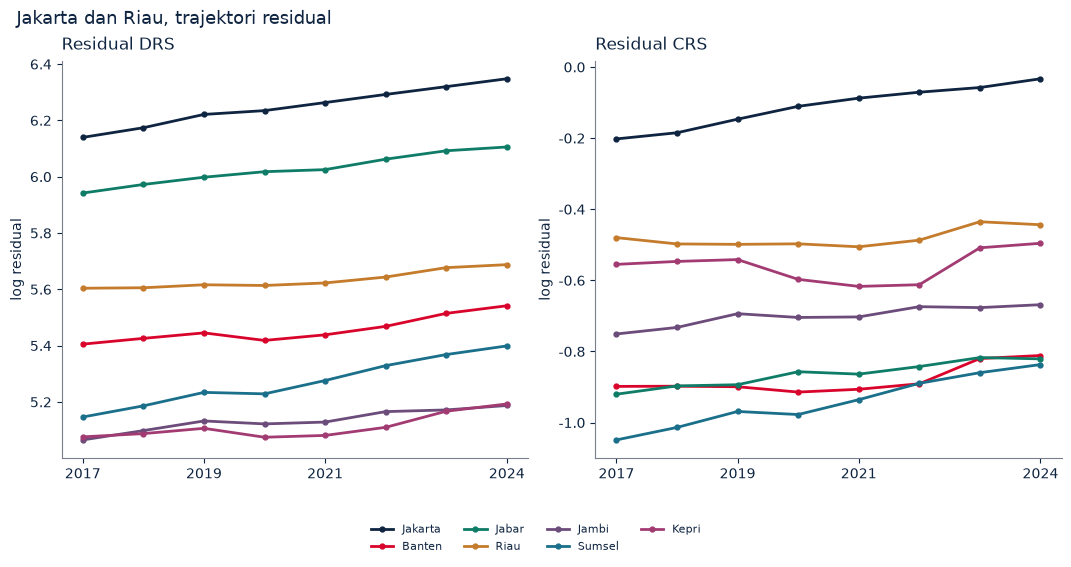

01 Data/TFP/output/tipologi/tip_A_komposisi.png


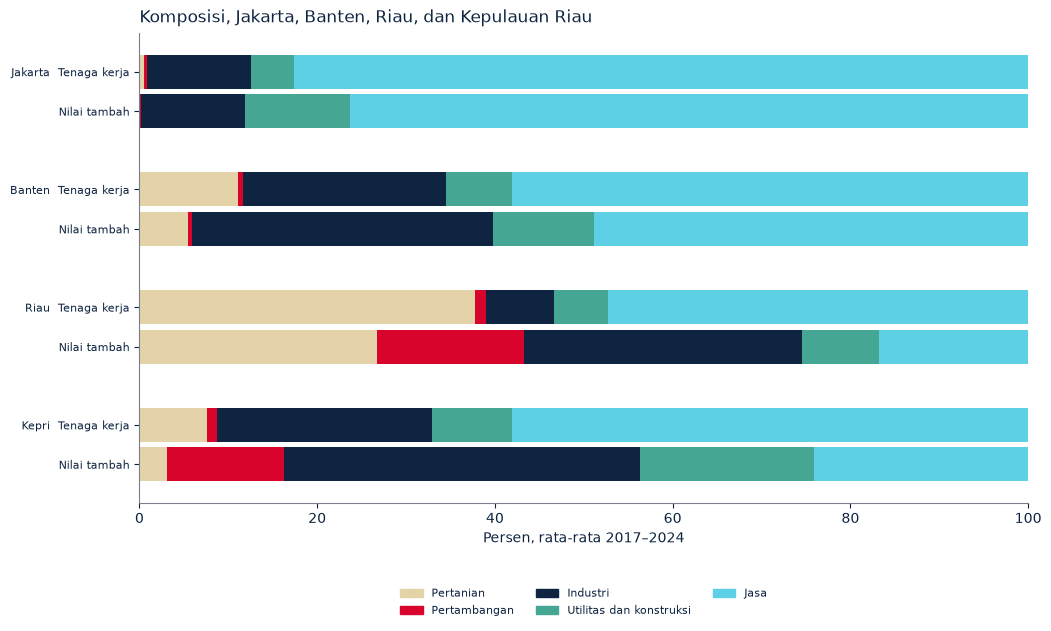

In [4]:
lihat("A")
# Jakarta dibanding Banten dan Jawa Barat. Riau dibanding Jambi, Sumatera Selatan, dan Kepulauan Riau.
trajektori([31, 36, 32, 14, 15, 16, 21], "tip_A_trajektori.png", "Jakarta dan Riau, trajektori residual")
komposisi([31, 36, 14, 21], "tip_A_komposisi.png", "Komposisi, Jakarta, Banten, Riau, dan Kepulauan Riau")


## B. IRS dengan konvergensi yang belum lengkap

Nama kelompok menyebut IRS. Selang 95% yang memuat 1 tidak dipindahkan ke kelompok lain. Maluku Utara dibanding Maluku. Sulawesi Tengah dibanding tiga tetangga Sulawesi. PMTB di gambar adalah arus, bukan stok.


  short      uji      rts   rts_lo   rts_hi  rank_drs  rank_crs  selisih
  Malut      IRS 3.201173 2.102953 4.299394        34        30        4
Sulteng memuat 1 3.059816 0.144916 5.974716        19        15        4
Uji RTS tidak sama dengan klaim pada nama kelompok. Keanggotaan tidak dipindahkan.
  Sulteng: klaim IRS, estimasi memuat 1, RTS 3,06 [0,14; 5,97]
       Provinsi                                                                                                              Pertanyaan investasi                                                                            Ukuran keberhasilan
   Maluku Utara Apakah respons ekspansi yang tinggi menaikkan produktivitas pekerja, kemampuan pemasok, dan pendapatan yang tertahan di provinsi? Output per pekerja, upah riil, dan apakah tenaga kerja bergerak bersama nilai tambah sektoral.
Sulawesi Tengah                                           Apakah ekspansi industri menaikkan kemampuan di luar kegiatan yang tumbuh paling cepat? Output 

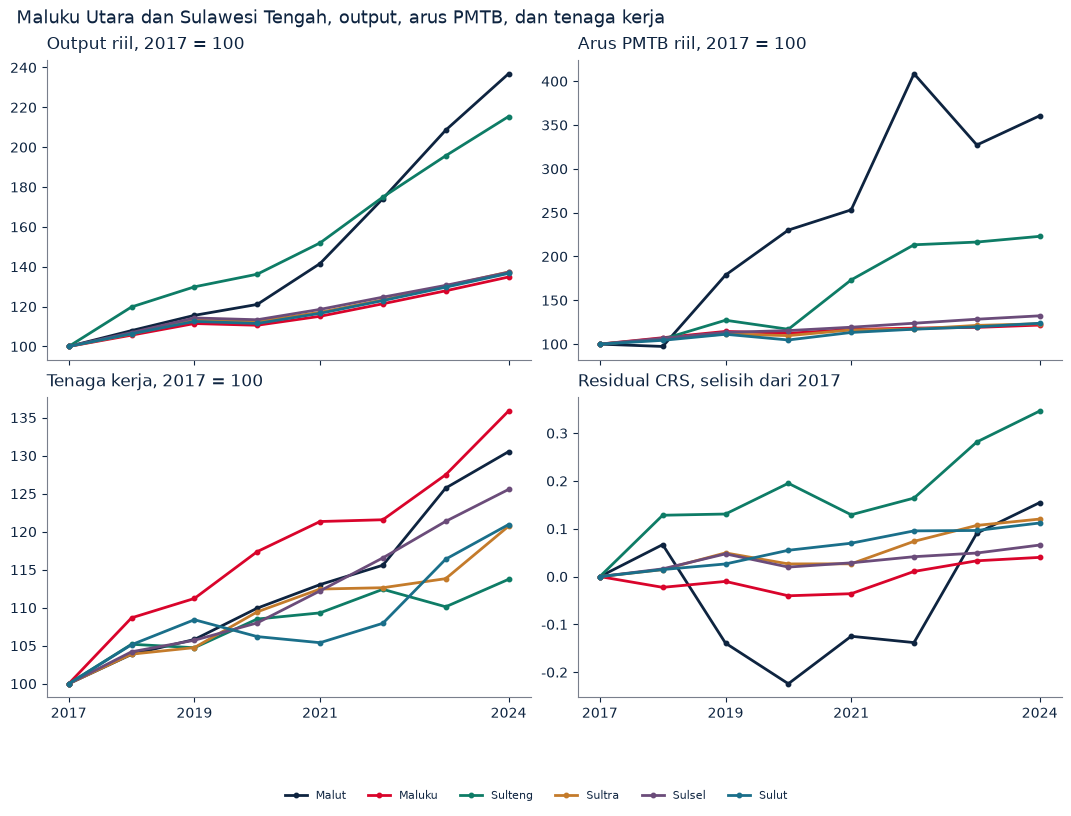

01 Data/TFP/output/tipologi/tip_B_kontribusi.png


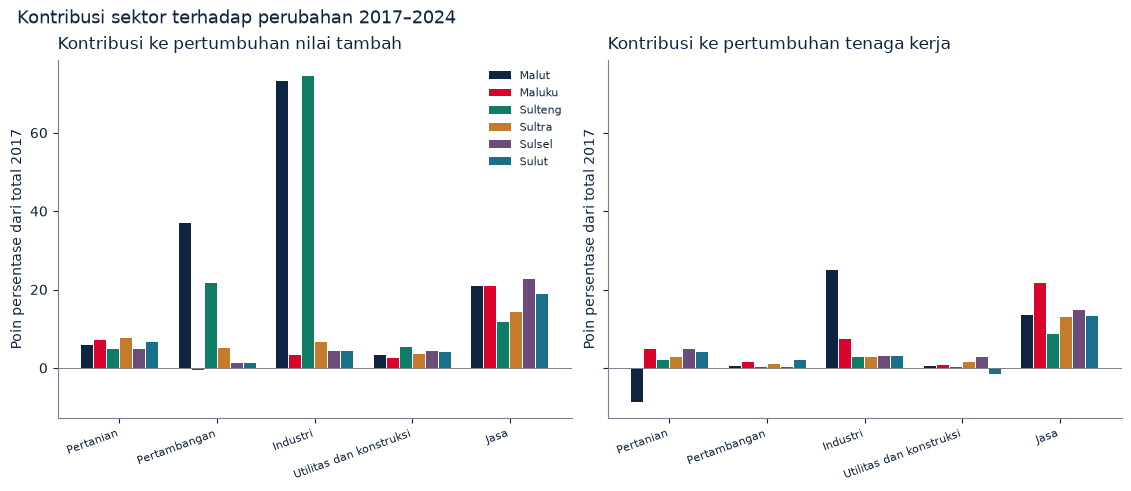

In [5]:
lihat("B")
# Maluku Utara dibanding Maluku. Sulawesi Tengah dibanding Sulawesi Tenggara, Selatan, dan Utara.
indeks_input([82, 81, 72, 74, 73, 71], "tip_B_input.png", "Maluku Utara dan Sulawesi Tengah, output, arus PMTB, dan tenaga kerja")
kontribusi([82, 81, 72, 74, 73, 71], "tip_B_kontribusi.png", "Kontribusi sektor terhadap perubahan 2017–2024")


## C. Posisi CRS kuat

Nama kelompok menyebut respons skala yang melemah. Gambar level–tren dan panah arus PMTB memeriksa posisi serta arahnya. Kalimantan Timur tetap terpisah dari Kalimantan Utara. Lingkaran putih pada panah tidak dipakai: panah bergerak dari 2017 ke 2024.


 short      uji      rts   rts_lo   rts_hi  rank_drs  rank_crs  selisih
Kaltim memuat 1 0.796474 0.573124 1.019823         4         2        2
 Kepri memuat 1 0.990864 0.811720 1.170007        13         6        7
Uji RTS tidak sama dengan klaim pada nama kelompok. Keanggotaan tidak dipindahkan.
  Kaltim: klaim DRS, estimasi memuat 1, RTS 0,80 [0,57; 1,02]
  Kepri: klaim DRS, estimasi memuat 1, RTS 0,99 [0,81; 1,17]
        Provinsi                                                                                                                                     Pertanyaan investasi                                                       Ukuran keberhasilan
Kalimantan Timur                                          Apakah ekonomi yang sudah produktif masih naik melalui utilisasi dan diversifikasi, bukan hanya tambahan input? Output per pekerja, tren residual, dan diversifikasi pangsa nilai tambah.
  Kepulauan Riau Mengapa posisi pada spesifikasi CRS relatif kuat, sementara respons terha

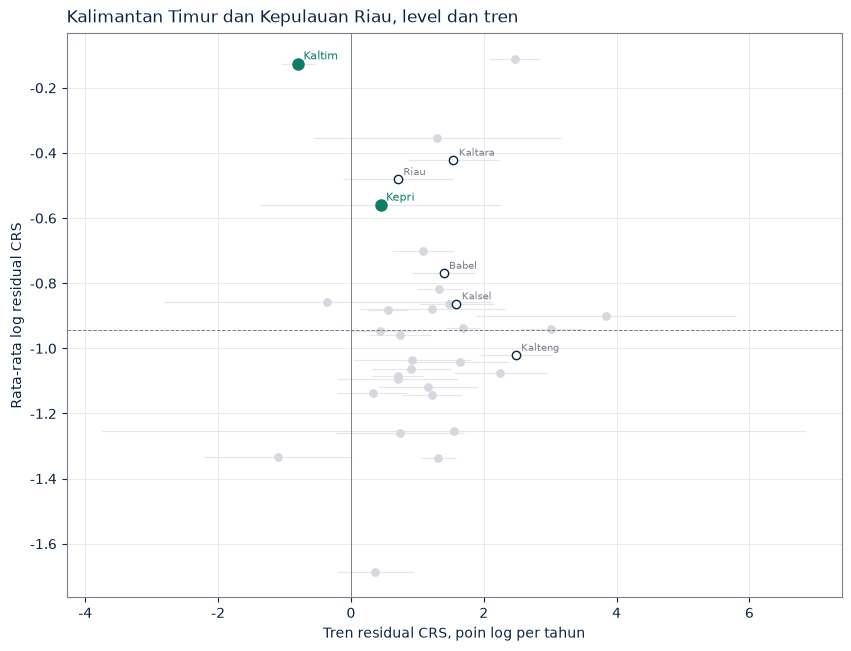

01 Data/TFP/output/tipologi/tip_C_panah.png


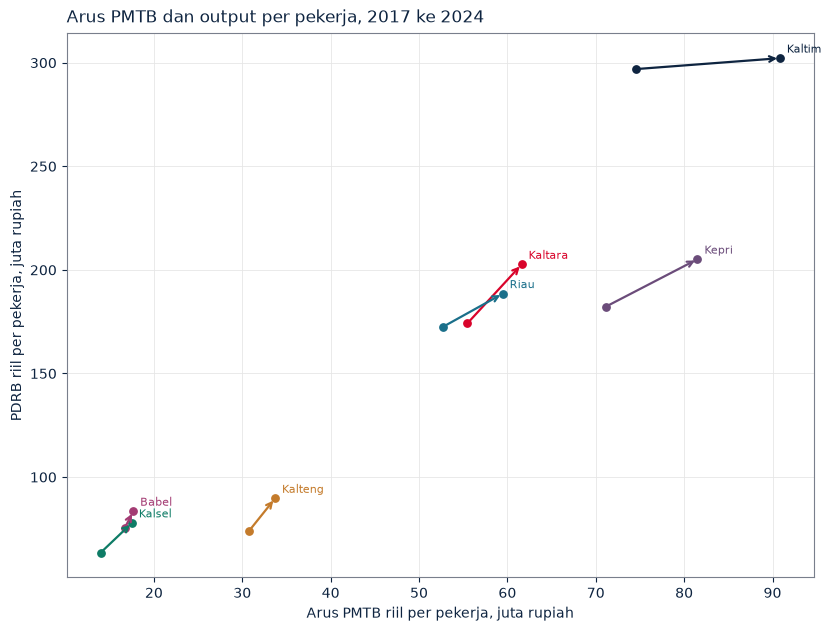

In [6]:
lihat("C")
level_tren([64, 21], "tip_C_level_tren.png", "Kalimantan Timur dan Kepulauan Riau, level dan tren", teman=[65, 63, 62, 14, 19])
panah([64, 65, 63, 62, 21, 14, 19], "tip_C_panah.png", "Arus PMTB dan output per pekerja, 2017 ke 2024")


## D. Keunggulan yang besar pada spesifikasi CRS

Selisih peringkat bukan kenaikan produktivitas. Panel kiri adalah level log. Panel kanan adalah peringkat. Pangsa nilai tambah digambar di samping pangsa tenaga kerja, termasuk bila jasa atau industri lebih besar daripada tambang.


      short      uji      rts    rts_lo   rts_hi  rank_drs  rank_crs  selisih
    Kaltara memuat 1 1.358682  0.500598 2.216765        23         4       19
      Babel memuat 1 1.187498  0.099909 2.275087        26         8       18
Papua Barat memuat 1 0.622665 -0.636785 1.882115        17         3       14
Uji RTS sejalan dengan nama kelompok, atau kelompok ini tidak mengunci satu kelas.
                 Provinsi                                                                                                  Pertanyaan investasi                                                                                  Ukuran keberhasilan
         Kalimantan Utara Apakah keunggulan yang tampak pada spesifikasi CRS sampai ke pekerja dan usaha lokal, mengingat institusi yang lemah? Selisih pangsa nilai tambah dan tenaga kerja, upah riil, serta ekuitas, institusi, dan konektivitas.
Kepulauan Bangka Belitung                  Apakah keunggulan pada spesifikasi CRS dapat menjadi basis usaha dan lap

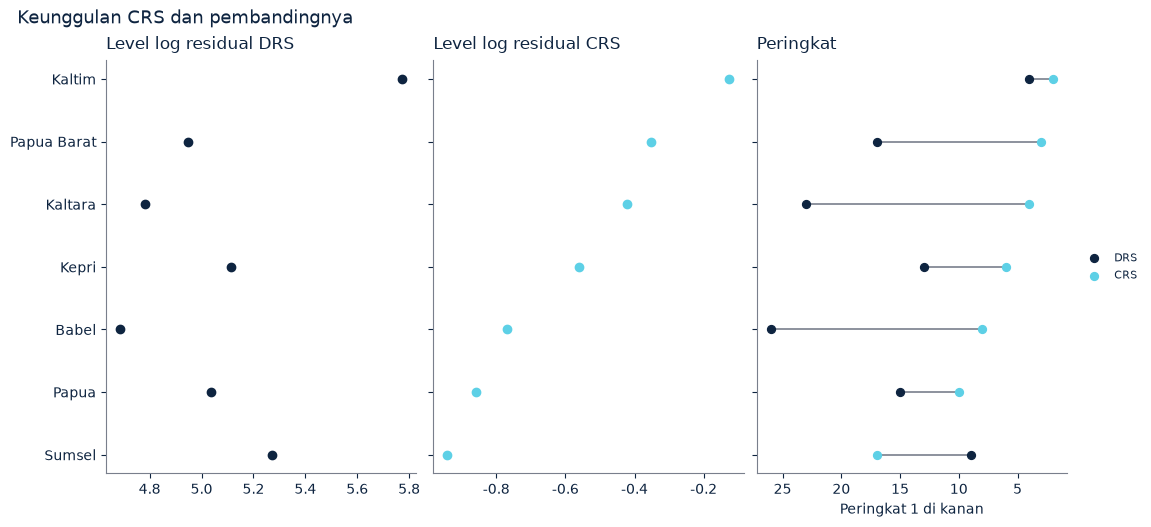

01 Data/TFP/output/tipologi/tip_D_konsentrasi.png


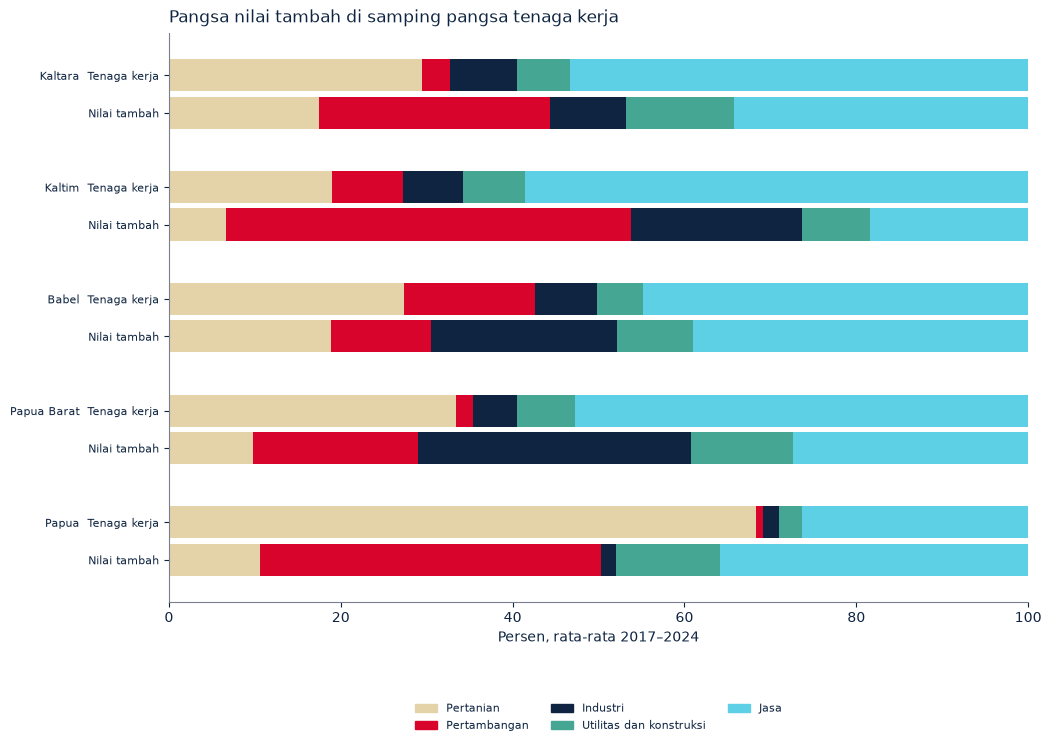

In [7]:
lihat("D")
# Level dan peringkat digambar terpisah. Keduanya tidak dikurangkan.
level_peringkat([65, 64, 19, 16, 21, 91, 94], "tip_D_level_peringkat.png", "Keunggulan CRS dan pembandingnya")
komposisi([65, 64, 19, 91, 94], "tip_D_konsentrasi.png", "Pangsa nilai tambah di samping pangsa tenaga kerja")


## E. Posisi lebih kuat pada spesifikasi DRS

Sumbu mendatar adalah selisih peringkat. Sumbu tegak adalah output per pekerja, supaya skala kegiatan tidak tertukar dengan produktivitas di dalam sektor. Pilar dan nilai tambah per pekerja menyusul.


 short      uji      rts   rts_lo   rts_hi  rank_drs  rank_crs  selisih
Jateng memuat 1 1.172197 0.840806 1.503588         5        23      -18
 Jabar      IRS 1.689049 1.266309 2.111790         3        12       -9
 Jatim memuat 1 1.198692 0.492133 1.905250         2         9       -7
Sulsel      IRS 1.188240 1.020917 1.355562        10        19       -9
Sumsel      IRS 3.108899 2.423553 3.794245         9        17       -8
 Sumut memuat 1 1.061575 0.831253 1.291898         7        14       -7
Banten memuat 1 0.760955 0.226486 1.295424         8        13       -5
Uji RTS sejalan dengan nama kelompok, atau kelompok ini tidak mengunci satu kelas.
        Provinsi                                                                                                                           Pertanyaan investasi                                                            Ukuran keberhasilan
     Jawa Tengah Mengapa skala kegiatan berjalan bersama posisi CRS yang jauh lebih rendah: karena kom

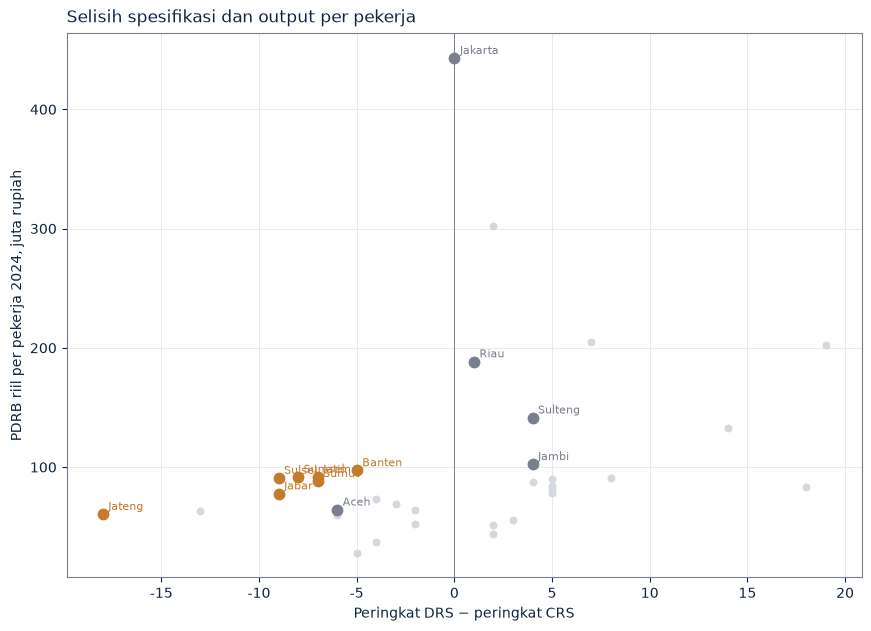

01 Data/TFP/output/tipologi/tip_E_pilar.png


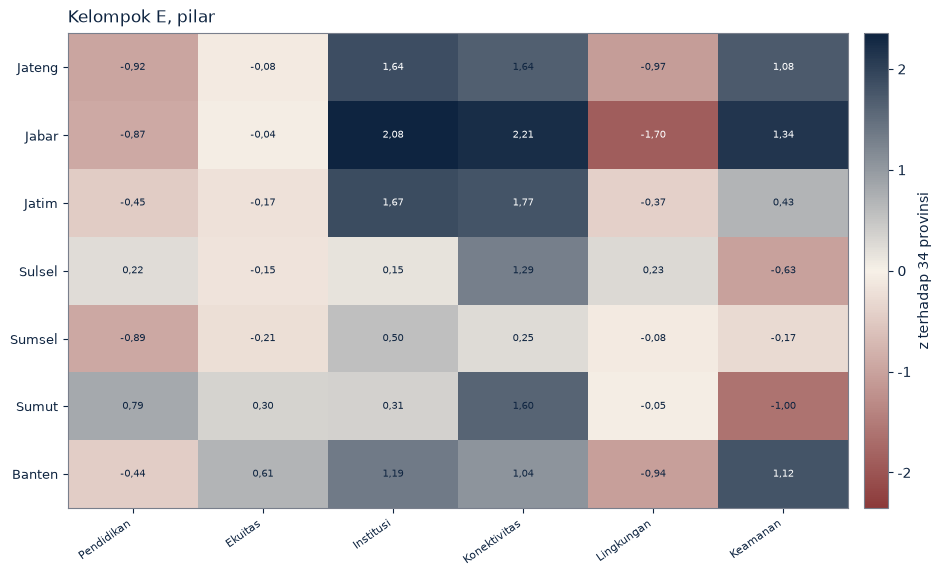

01 Data/TFP/output/tipologi/tip_E_lp.png


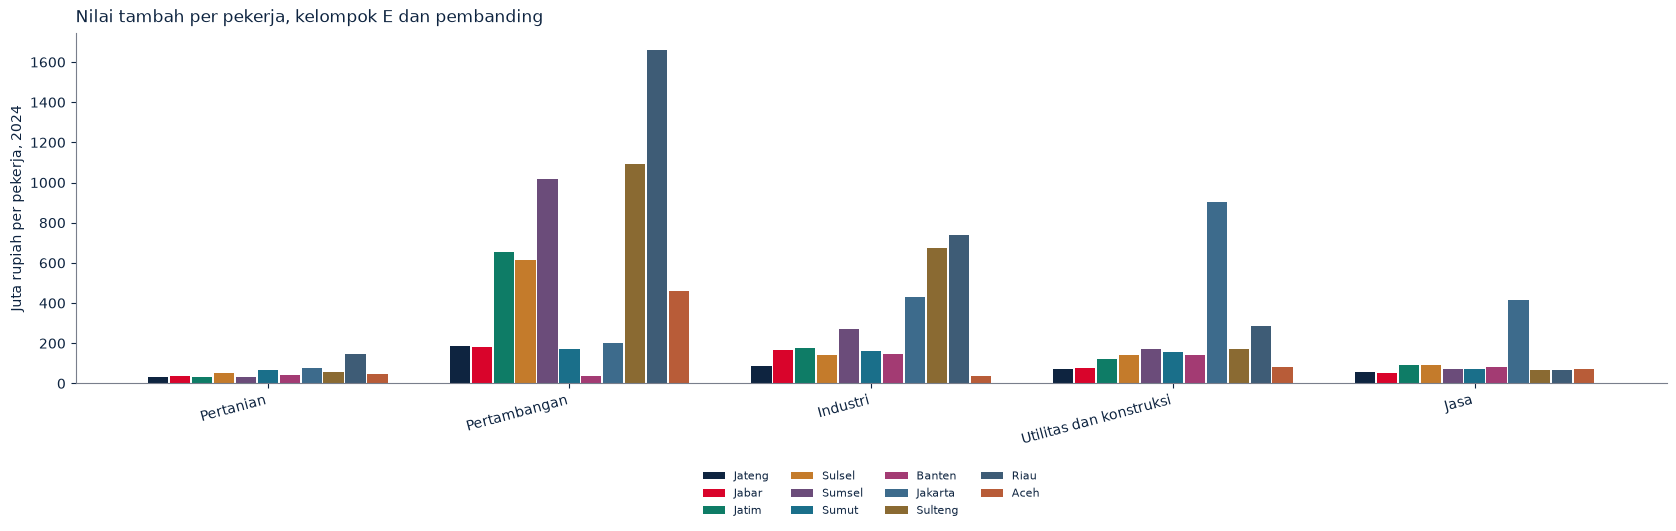

In [8]:
lihat("E")
fokus = [33, 32, 35, 73, 16, 12, 36]
pembanding = [31, 72, 14, 15, 11]
fig, ax = plt.subplots(figsize=(8.6, 6.2), layout="constrained")
ax.scatter(prov.selisih, prov.yl24, s=22, c="#D5D8DE", zorder=1)
for r in prov.itertuples(index=False):
    if r.code not in fokus + pembanding:
        continue
    warna = WARNA_KAT[r.kode_kat] if r.code in fokus else GRAY
    ax.scatter(r.selisih, r.yl24, s=56, c=warna, zorder=2)
    ax.annotate(r.short, (r.selisih, r.yl24), textcoords="offset points", xytext=(4, 3), fontsize=8, color=warna)
ax.axvline(0, color=GRAY, lw=0.7)
ax.set_xlabel("Peringkat DRS − peringkat CRS")
ax.set_ylabel("PDRB riil per pekerja 2024, juta rupiah")
judul(ax, "Selisih spesifikasi dan output per pekerja")
simpan(fig, "tip_E_selisih.png")
pilar = [
    ("pil_pendidikan", "Pendidikan", 1), ("pil_equity", "Ekuitas", 1),
    ("pil_institusi", "Institusi", 1), ("pil_konektivitas", "Konektivitas", 1),
    ("pil_lingkungan", "Lingkungan", 1), ("pil_keamanan", "Keamanan", 1),
]
heatmap_kode(fokus, pilar, "tip_E_pilar.png", "Kelompok E, pilar")
lp_sektor(fokus + [31, 72, 14, 11], "tip_E_lp.png", "Nilai tambah per pekerja, kelompok E dan pembanding")


## F. Posisi CRS lebih lemah

Nama kelompok menyebut DRS. Hutan selang menunjukkan uji yang sebenarnya. Pertanian dan pertambangan tidak digabung. NTT dibanding NTB dan Bali. Lampung dibanding Sumatera Selatan dan Bengkulu.


  short      uji      rts   rts_lo   rts_hi  rank_drs  rank_crs  selisih
Lampung      IRS 1.253957 1.032369 1.475544        12        25      -13
 Kalbar memuat 1 1.145600 0.719346 1.571853        20        26       -6
    NTT      IRS 1.312615 1.089404 1.535827        29        34       -5
    NTB memuat 1 0.551389 0.065854 1.036923        28        32       -4
 Sumbar memuat 1 1.124327 0.908483 1.340170        14        18       -4
Uji RTS tidak sama dengan klaim pada nama kelompok. Keanggotaan tidak dipindahkan.
  Lampung: klaim DRS, estimasi IRS, RTS 1,25 [1,03; 1,48]
  Kalbar: klaim DRS, estimasi memuat 1, RTS 1,15 [0,72; 1,57]
  NTT: klaim DRS, estimasi IRS, RTS 1,31 [1,09; 1,54]
  NTB: klaim DRS, estimasi memuat 1, RTS 0,55 [0,07; 1,04]
  Sumbar: klaim DRS, estimasi memuat 1, RTS 1,12 [0,91; 1,34]
           Provinsi                                                                                                       Pertanyaan investasi                                          

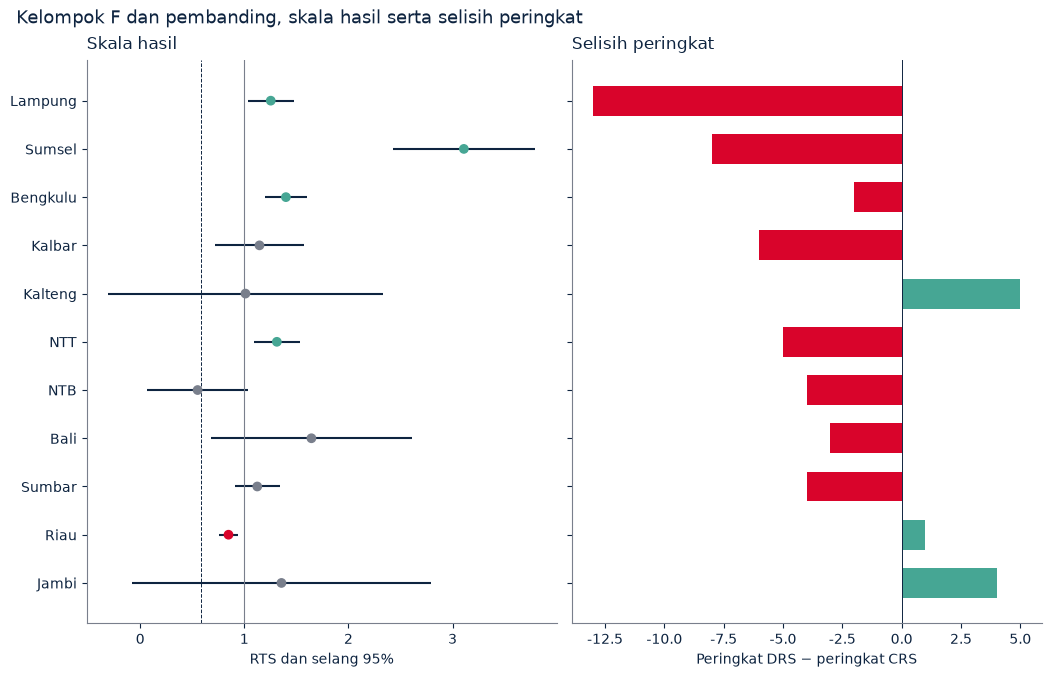

01 Data/TFP/output/tipologi/tip_F_primer.png


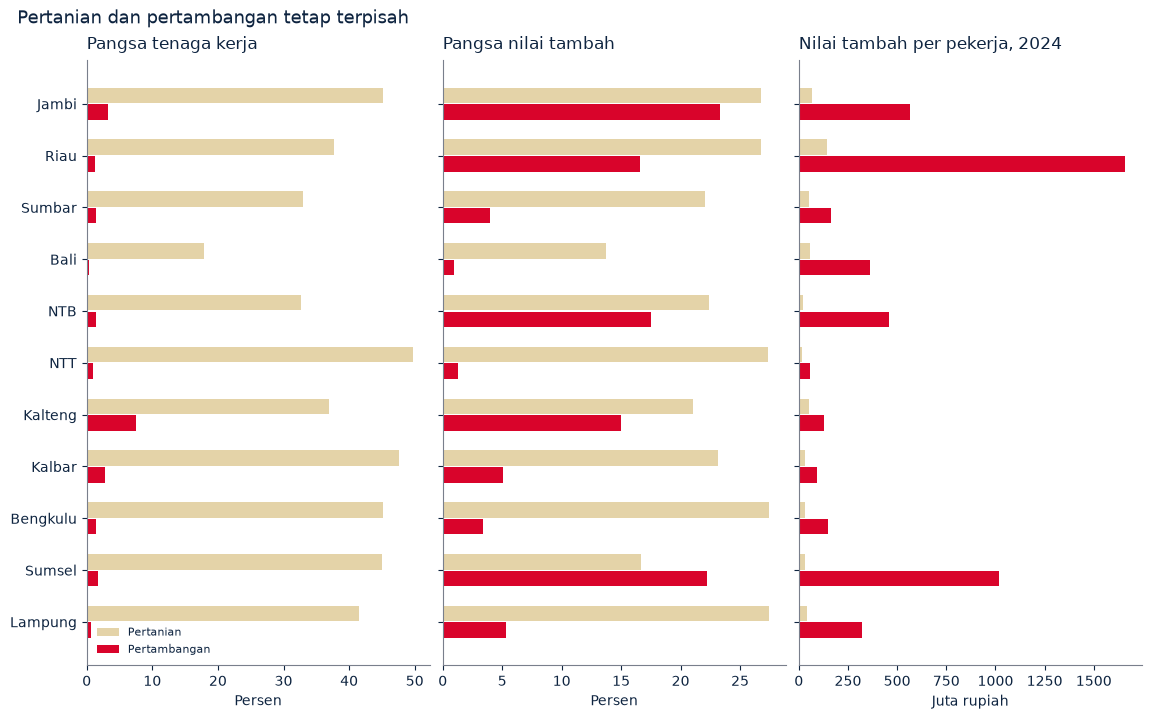

In [9]:
lihat("F")
kode = [18, 16, 17, 61, 62, 53, 52, 51, 13, 14, 15]
forest(kode, "tip_F_forest.png", "Kelompok F dan pembanding, skala hasil serta selisih peringkat")
primer(kode, "tip_F_primer.png", "Pertanian dan pertambangan tetap terpisah")


## G. Dominasi tenaga kerja primer

Papua sendiri di kelompok ini. Pembanding geografis adalah Papua Barat. Pembanding struktur adalah NTT dan Kalimantan Barat. Kemiskinan tidak di-z bersama pilar, karena arahnya berlawanan.


short      uji      rts   rts_lo   rts_hi  rank_drs  rank_crs  selisih
Papua memuat 1 0.875483 0.162588 1.588377        15        10        5
Uji RTS tidak sama dengan klaim pada nama kelompok. Keanggotaan tidak dipindahkan.
  Papua: klaim DRS, estimasi memuat 1, RTS 0,88 [0,16; 1,59]
Provinsi                                                                                                                          Pertanyaan investasi                                                                    Ukuran keberhasilan
   Papua Siapa yang ikut serta dalam kegiatan produktif: kegiatan bernilai tambah tinggi, atau basis kerja yang menampung sebagian besar rumah tangga? Pangsa tenaga kerja versus pangsa nilai tambah, upah riil, kemiskinan, dan pendidikan.
01 Data/TFP/output/tipologi/tip_G_mismatch.png


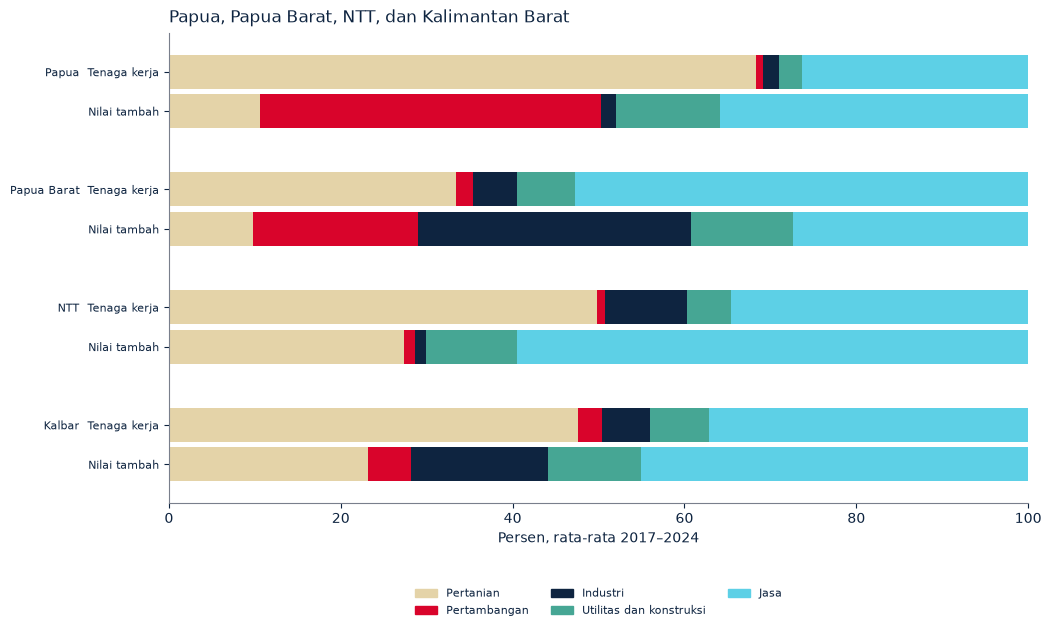

01 Data/TFP/output/tipologi/tip_G_profil.png


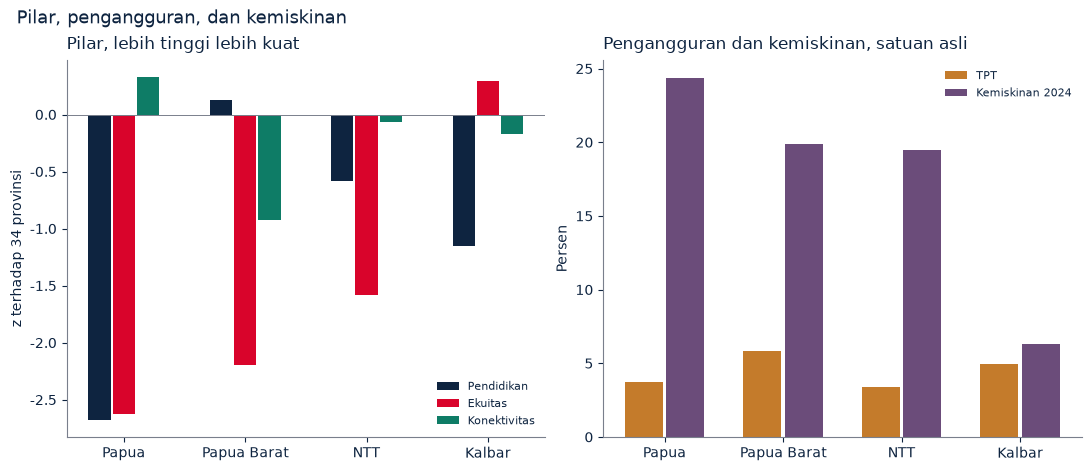

In [10]:
lihat("G")
komposisi([94, 91, 53, 61], "tip_G_mismatch.png", "Papua, Papua Barat, NTT, dan Kalimantan Barat")
profil_batang([94, 91, 53, 61], "tip_G_profil.png", "Pilar, pengangguran, dan kemiskinan")


## H. Fondasi tertentu, posisi produktivitas lebih lemah

Lama sekolah dibanding residual, lalu dibanding TPT, upah riil, dan output per pekerja. Tidak ada data okupasi atau status formal di panel ini. DI Yogyakarta dibanding Jawa Tengah. Maluku dibanding Maluku Utara. Aceh dibanding Sumatera Utara.


 short      uji      rts    rts_lo   rts_hi  rank_drs  rank_crs  selisih
   DIY memuat 1 0.882111 -0.599412 2.363635        22        24       -2
Maluku memuat 1 1.060121  0.493081 1.627161        33        31        2
  Aceh memuat 1 1.473694  0.416444 2.530944        21        27       -6
Uji RTS sejalan dengan nama kelompok, atau kelompok ini tidak mengunci satu kelas.
     Provinsi                                                                                                                       Pertanyaan investasi                                                                               Ukuran keberhasilan
DI Yogyakarta                                                            Di mana konversi lama sekolah menjadi pekerjaan dan output per pekerja melemah? Apakah lama sekolah diikuti upah riil yang lebih tinggi dan output per pekerja yang lebih tinggi.
       Maluku Mengapa kekuatan pendidikan tidak tampak sebagai posisi produktivitas yang tinggi, berbeda dari Maluku Utara 

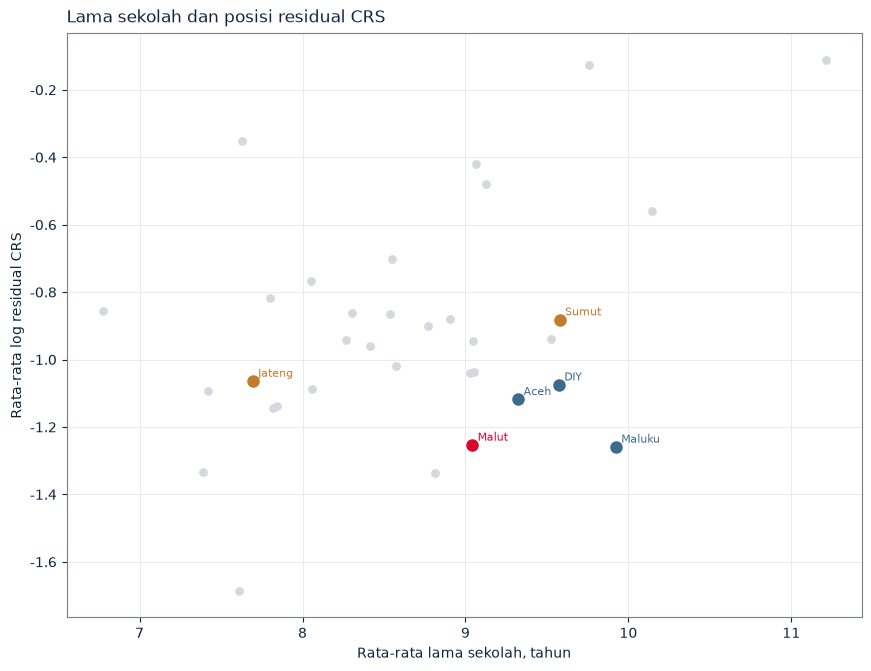

01 Data/TFP/output/tipologi/tip_H_konversi.png


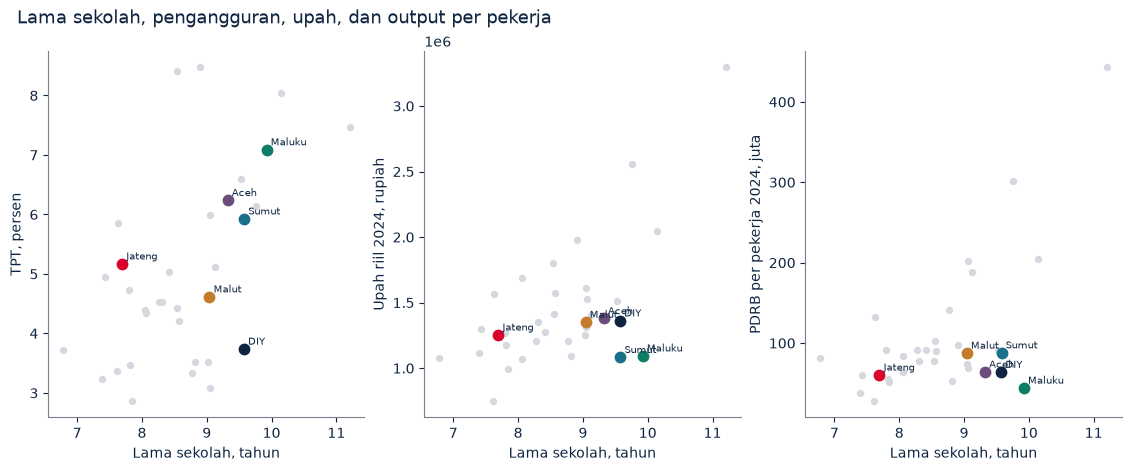

In [11]:
lihat("H")
sekolah([34, 81, 11, 33, 82, 12], "tip_H_sekolah.png", "Lama sekolah dan posisi residual CRS")
konversi([34, 33, 81, 82, 11, 12], "tip_H_konversi.png", "Lama sekolah, pengangguran, upah, dan output per pekerja")


## I. Keunggulan CRS yang moderat

Kuadran memakai seluruh provinsi sebagai latar. Lima panel kecil menjaga tiap jalur tetap terlihat. Sulawesi Tenggara dan Sulawesi Utara diuji terhadap klaim bahwa selang RTS memuat 1.


  short      uji      rts    rts_lo   rts_hi  rank_drs  rank_crs  selisih
  Jambi memuat 1 1.356695 -0.082922 2.796313        11         7        4
Kalteng memuat 1 1.010916 -0.308716 2.330548        25        20        5
 Kalsel memuat 1 0.485589 -0.527251 1.498430        16        11        5
  Sulut      IRS 1.507110  1.179540 1.834680        24        16        8
 Sultra      IRS 1.548680  1.166761 1.930599        27        22        5
Uji RTS tidak sama dengan klaim pada nama kelompok. Keanggotaan tidak dipindahkan.
  Sulut: klaim memuat 1, estimasi IRS, RTS 1,51 [1,18; 1,83]
  Sultra: klaim memuat 1, estimasi IRS, RTS 1,55 [1,17; 1,93]
          Provinsi                                                                                                                      Pertanyaan investasi                                           Ukuran keberhasilan
             Jambi               Kegiatan produktif mana yang dapat meluas, dan apakah ia terhubung ke ekonomi lokal meski pangsa t

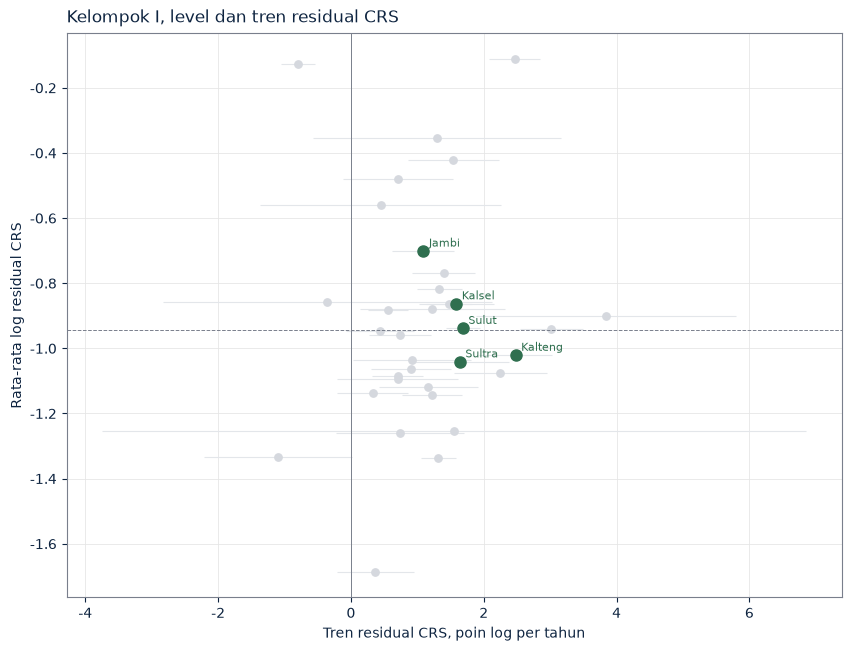

01 Data/TFP/output/tipologi/tip_I_kecil.png


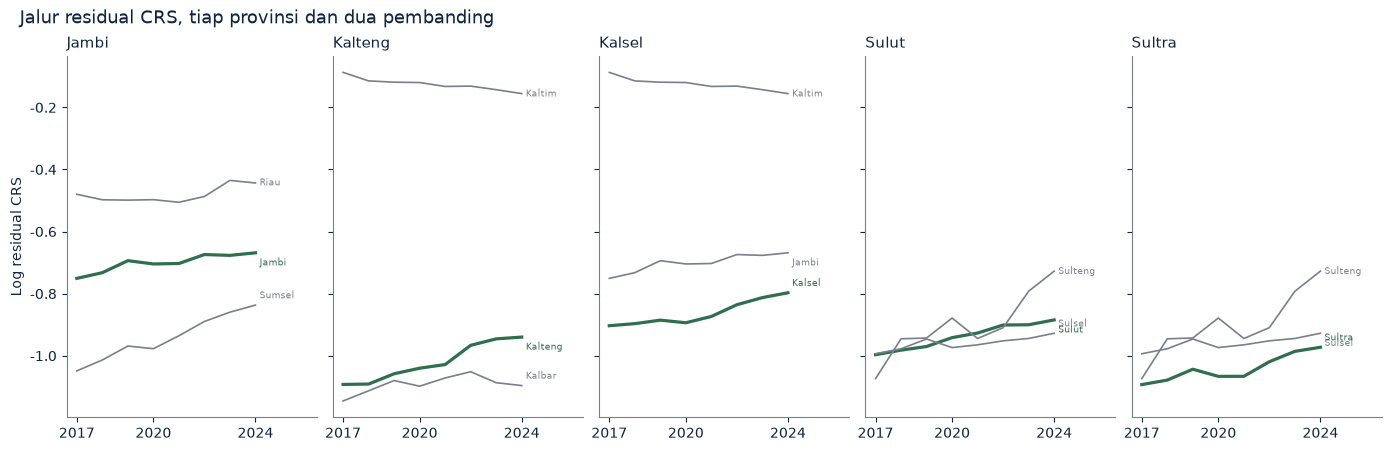

In [12]:
lihat("I")
level_tren([15, 62, 63, 71, 74], "tip_I_kuadran.png", "Kelompok I, level dan tren residual CRS")
jalur_kecil(
    [(15, [14, 16]), (62, [64, 61]), (63, [64, 15]), (71, [72, 73]), (74, [72, 73])],
    "tip_I_kecil.png", "Jalur residual CRS, tiap provinsi dan dua pembanding",
)


## J. Posisi lebih rendah, selisih peringkat terbatas

Bali tidak dirata-ratakan dengan Bengkulu, Gorontalo, dan Sulawesi Barat. Tiga provinsi itu dilihat pada pertanian dan pertambangan. Bali dilihat pada perdagangan, transportasi, akomodasi, dan jasa lain, dibanding NTB dan DI Yogyakarta. Pangsa jasa adalah bagian dari seluruh tenaga kerja.


    short      uji      rts   rts_lo   rts_hi  rank_drs  rank_crs  selisih
 Bengkulu      IRS 1.399611 1.194377 1.604845        31        33       -2
Gorontalo      IRS 1.507848 1.347699 1.667997        32        29        3
   Sulbar memuat 1 1.183985 0.897658 1.470313        30        28        2
     Bali memuat 1 1.644645 0.680022 2.609268        18        21       -3
Uji RTS tidak sama dengan klaim pada nama kelompok. Keanggotaan tidak dipindahkan.
  Bengkulu: klaim memuat 1, estimasi IRS, RTS 1,40 [1,19; 1,60]
  Gorontalo: klaim memuat 1, estimasi IRS, RTS 1,51 [1,35; 1,67]
      Provinsi                                                                                                                                             Pertanyaan investasi                                                                        Ukuran keberhasilan
      Bengkulu                                      Fondasi produktif mana yang paling membatasi, mengingat institusi yang lemah dan posisi yang r

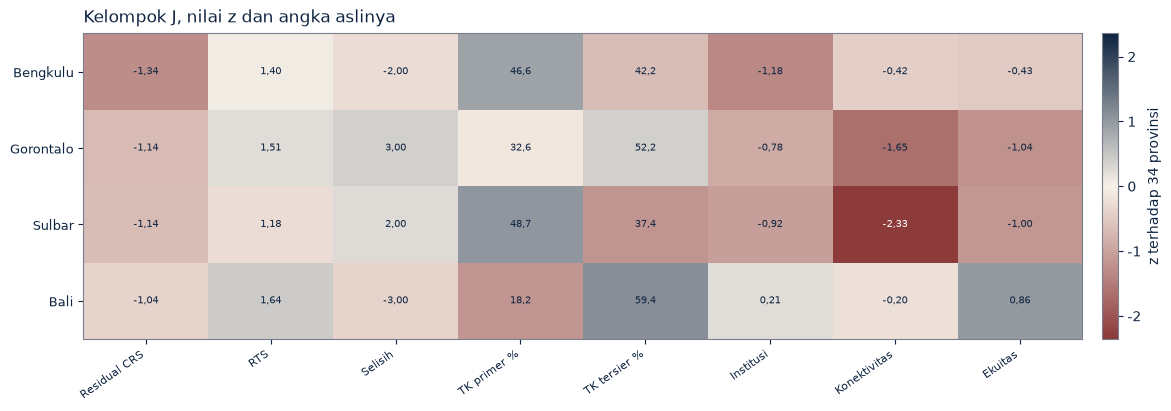

01 Data/TFP/output/tipologi/tip_J_sektor.png


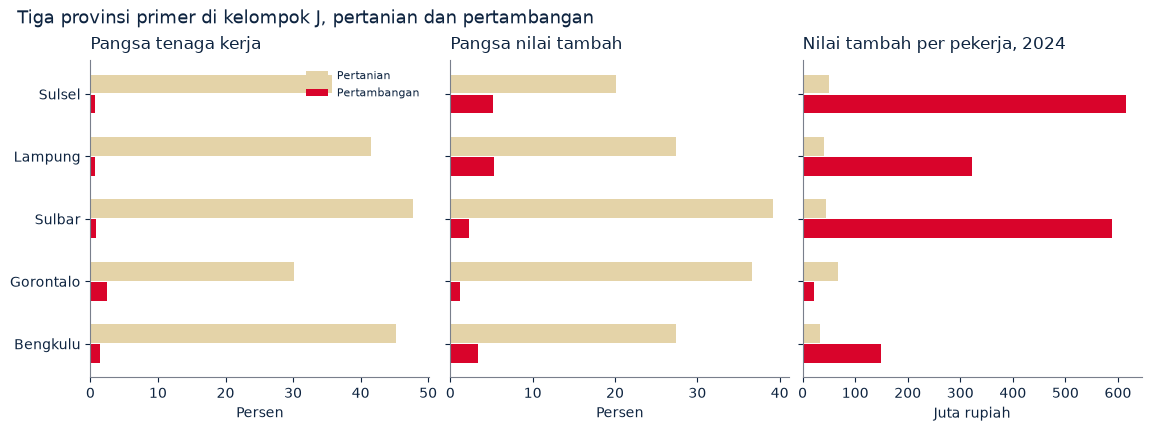

Code_Prov              DIY   Bali    NTB
kelompok                                
Akomodasi dan makan  0.111  0.151  0.059
Jasa lain            0.243  0.220  0.187
Perdagangan          0.197  0.205  0.190
Transportasi         0.043  0.044  0.028
01 Data/TFP/output/tipologi/tip_J_bali.png


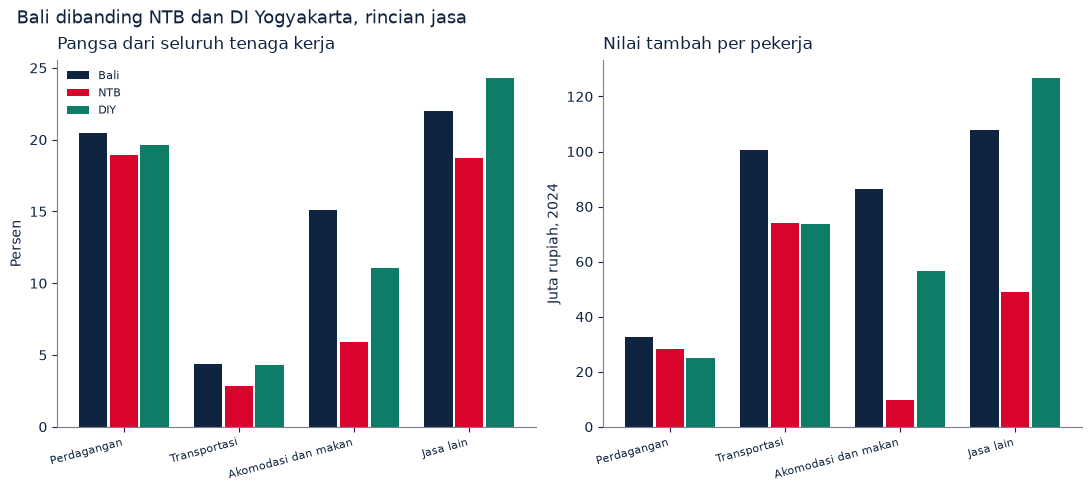

In [13]:
lihat("J")
kolom = [
    ("tfp_crs", "Residual CRS", 1), ("rts", "RTS", 1), ("selisih", "Selisih", 1),
    ("tk_primer", "TK primer %", 100), ("tk_tersier", "TK tersier %", 100),
    ("pil_institusi", "Institusi", 1), ("pil_konektivitas", "Konektivitas", 1),
    ("pil_equity", "Ekuitas", 1),
]
heatmap_kode([17, 75, 76, 51], kolom, "tip_J_kendala.png", "Kelompok J, nilai z dan angka aslinya")
primer([17, 75, 76, 18, 73], "tip_J_sektor.png", "Tiga provinsi primer di kelompok J, pertanian dan pertambangan")
rinci = jasa[(jasa.Year == 2024) & (jasa.Code_Prov.isin([51, 52, 34]))]
print(rinci.pivot(index="kelompok", columns="Code_Prov", values="share_tk_semua").rename(columns=SHORT).round(3))
gambar_jasa([51, 52, 34], "tip_J_bali.png", "Bali dibanding NTB dan DI Yogyakarta, rincian jasa")
